
# SOLUÇÕES EM ENERGIAS RENOVÁVEIS E SUSTENTÁVEIS
## Análise de Dados e Machine Learning em Energia

Este notebook contém cinco exercícios com base em dados públicos do **ONS (Operador Nacional do Sistema Elétrico)**.  
O objetivo é explorar, analisar e modelar dados de geração de energia no Brasil, aplicando técnicas de **Python, análise de dados e aprendizado de máquina**.

### Fonte dos dados
O dataset utilizado está disponível no portal aberto do ONS:  
[CAPACIDADE_GERACAO.csv](https://ons-aws-prod-opendata.s3.amazonaws.com/dataset/capacidade-geracao/CAPACIDADE_GERACAO.csv)

Este arquivo contém informações sobre as usinas brasileiras, incluindo:
- Tipo de geração (hidráulica, solar, eólica, térmica etc.)
- Capacidade instalada (MW)
- Data de início de operação
- Estado de localização

---



# Exercício 1 – Exploração da Matriz Energética Brasileira

### Contexto
O Brasil possui uma matriz energética diversificada. Entender a evolução da capacidade instalada por fonte é essencial para analisar a transição energética.

### Atividade
1. Carregar o dataset de capacidade de geração.  
2. Explorar as colunas e verificar os tipos de geração disponíveis.  
3. Criar gráficos de linha mostrando a evolução da capacidade instalada de cada fonte ao longo dos anos.  
4. Pergunta: Qual fonte cresceu mais nos últimos 10 anos?


Colunas disponíveis no DataFrame:
['id_subsistema', 'nom_subsistema', 'id_estado', 'nom_estado', 'nom_modalidadeoperacao', 'nom_agenteproprietario', 'nom_agenteoperador', 'nom_tipousina', 'nom_usina', 'ceg', 'nom_unidadegeradora', 'cod_equipamento', 'num_unidadegeradora', 'nom_combustivel', 'dat_entradateste', 'dat_entradaoperacao', 'dat_desativacao', 'val_potenciaefetiva']

Tipos de geração disponíveis:
['HIDROELÃ\x89TRICA' 'TÃ\x89RMICA' 'EOLIELÃ\x89TRICA' 'NUCLEAR'
 'FOTOVOLTAICA']


/tmp/ipython-input-515210371.py:80: UserWarning: Glyph 137 (\x89) missing from font(s) Liberation Sans.
  plt.tight_layout()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 137 (\x89) missing from font(s) Liberation Sans.
  fig.canvas.print_figure(bytes_io, **kw)


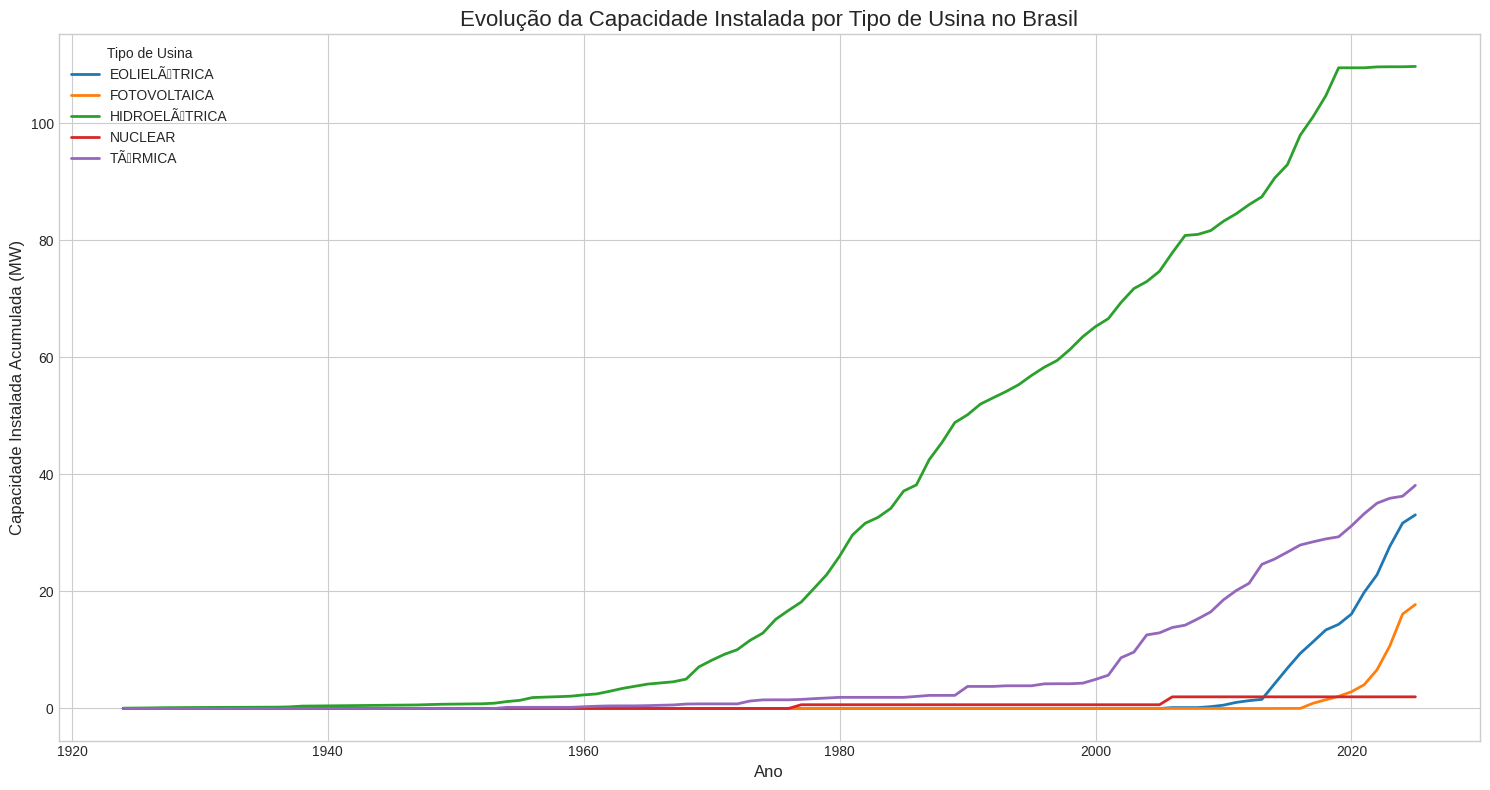


Crescimento nos Últimos 10 Anos por Tipo de Usina:
nom_tipousina
EOLIELÃTRICA     26.193445
FOTOVOLTAICA      17.758321
HIDROELÃTRICA    16.774052
TÃRMICA          11.406684
NUCLEAR            0.000000
dtype: float64

A fonte que mais cresceu em capacidade instalada nos últimos 10 anos foi: 'EOLIELÃTRICA' com um aumento de 26.19 MW.


In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import unicodedata

# Função para normalizar os nomes das colunas
def normalize_column_names(columns):
    return [
        unicodedata.normalize('NFKD', col)
        .encode('ascii', errors='ignore')
        .decode('utf-8')
        .strip()
        .lower()
        for col in columns
    ]

# 1 - Carregar o dataset
df = pd.read_csv('CAPACIDADE_GERACAO.csv', sep=';', encoding='latin-1')

# Padronizar os nomes das colunas
df.columns = normalize_column_names(df.columns)

# Mostrar colunas disponíveis
print("Colunas disponíveis no DataFrame:")
print(df.columns.tolist())

# Verificar se as colunas necessárias estão presentes
if 'dat_entradaoperacao' not in df.columns or 'val_potenciaefetiva' not in df.columns:
    raise ValueError("Colunas obrigatórias não encontradas. Verifique o nome das colunas no CSV.")

# Converter data para datetime
df['dat_entradaoperacao'] = pd.to_datetime(df['dat_entradaoperacao'], errors='coerce')

# Extrair o ano de operação
df['ano_operacao'] = df['dat_entradaoperacao'].dt.year

# Remover linhas com ano nulo
df.dropna(subset=['ano_operacao'], inplace=True)
df['ano_operacao'] = df['ano_operacao'].astype(int)

# Converter potência para float
df['val_potenciaefetiva'] = pd.to_numeric(df['val_potenciaefetiva'], errors='coerce')

# Remover valores nulos ou negativos
df = df[df['val_potenciaefetiva'] > 0]

# 2 - Explorar os tipos de geração
print("\nTipos de geração disponíveis:")
if 'nom_tipousina' in df.columns:
    print(df['nom_tipousina'].unique())
else:
    raise ValueError("Coluna 'nom_tipousina' não encontrada.")

# 3 - Evolução da capacidade instalada por tipo de geração

# Agrupar dados
evolucao_anual = (
    df.groupby(['ano_operacao', 'nom_tipousina'])['val_potenciaefetiva']
    .sum()
    .unstack()
    .fillna(0)
)

# Calcular acumulado
evolucao_acumulada_kw = evolucao_anual.cumsum()

# Converter para MW
evolucao_acumulada_mw = evolucao_acumulada_kw / 1000

# Plotar gráfico
plt.style.use('seaborn-v0_8-whitegrid')
fig, ax = plt.subplots(figsize=(15, 8))
evolucao_acumulada_mw.plot(kind='line', ax=ax, lw=2)

ax.set_title('Evolução da Capacidade Instalada por Tipo de Usina no Brasil', fontsize=16)
ax.set_xlabel('Ano', fontsize=12)
ax.set_ylabel('Capacidade Instalada Acumulada (MW)', fontsize=12)
ax.legend(title='Tipo de Usina')
ax.grid(True)
plt.tight_layout()
plt.show()

# 4 - Crescimento nos últimos 10 anos
ano_final = df['ano_operacao'].max()
ano_inicial = ano_final - 10

if ano_inicial not in evolucao_acumulada_mw.index or ano_final not in evolucao_acumulada_mw.index:
    raise ValueError(f"Anos {ano_inicial} ou {ano_final} não encontrados na série histórica.")

capacidade_inicio = evolucao_acumulada_mw.loc[ano_inicial]
capacidade_fim = evolucao_acumulada_mw.loc[ano_final]
crescimento_10_anos = capacidade_fim - capacidade_inicio

# Maior crescimento
fonte_maior_crescimento = crescimento_10_anos.idxmax()
valor_maior_crescimento = crescimento_10_anos.max()

# Exibir crescimento
print("\nCrescimento nos Últimos 10 Anos por Tipo de Usina:")
print(crescimento_10_anos.sort_values(ascending=False))

print(f"\nA fonte que mais cresceu em capacidade instalada nos últimos 10 anos foi: "
      f"'{fonte_maior_crescimento}' com um aumento de {valor_maior_crescimento:,.2f} MW.")



# Exercício 2 – Correlação entre Capacidade e Localização

### Contexto
A localização influencia o tipo de geração de energia (ex.: eólica no Nordeste, solar no Sudeste/Centro-Oeste, hidráulica no Norte).

### Atividade
1. Agrupar os dados por estado e tipo de geração.  
2. Montar gráficos de barras comparando a distribuição das fontes por estado.  
3. Calcular a participação percentual de cada fonte em cada estado.  
4. Pergunta: Quais estados são líderes em energia solar e eólica?


✅ Colunas disponíveis no DataFrame:
['id_subsistema', 'nom_subsistema', 'id_estado', 'nom_estado', 'nom_modalidadeoperacao', 'nom_agenteproprietario', 'nom_agenteoperador', 'nom_tipousina', 'nom_usina', 'ceg', 'nom_unidadegeradora', 'cod_equipamento', 'num_unidadegeradora', 'nom_combustivel', 'dat_entradateste', 'dat_entradaoperacao', 'dat_desativacao', 'val_potenciaefetiva']

🧭 Colunas identificadas automaticamente:
- Data de entrada: dat_entradateste
- Potência: val_potenciaefetiva
- Tipo de usina: nom_tipousina
- UF/Estado: id_estado

⚙️ Tipos de geração encontrados:
['HIDROELÃ\x89TRICA' 'TÃ\x89RMICA' 'EOLIELÃ\x89TRICA' 'NUCLEAR'
 'FOTOVOLTAICA']


/tmp/ipython-input-3663668795.py:84: UserWarning: Glyph 137 (\x89) missing from font(s) Liberation Sans.
  plt.tight_layout()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 137 (\x89) missing from font(s) Liberation Sans.
  fig.canvas.print_figure(bytes_io, **kw)


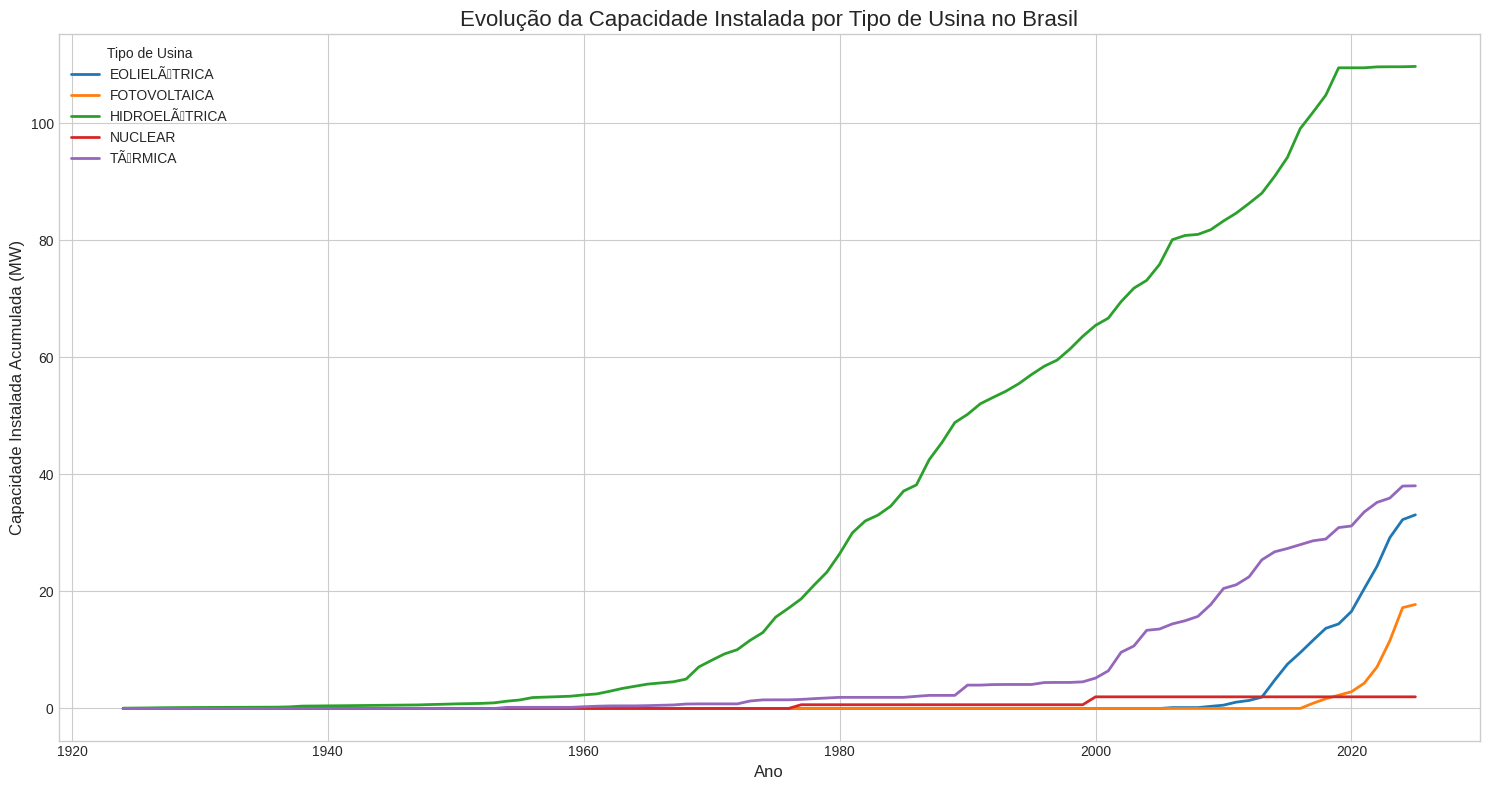


📈 Crescimento nos Últimos 10 Anos por Tipo de Usina (MW):
nom_tipousina
EOLIELÃTRICA     25.514325
FOTOVOLTAICA      17.758321
HIDROELÃTRICA    15.529962
TÃRMICA          10.707324
NUCLEAR            0.000000
dtype: float64

🚀 A fonte que mais cresceu em capacidade instalada nos últimos 10 anos foi: 'EOLIELÃTRICA' com um aumento de 25.51 MW.


/tmp/ipython-input-3663668795.py:121: UserWarning: Glyph 137 (\x89) missing from font(s) Liberation Sans.
  plt.tight_layout()


<Figure size 1400x800 with 0 Axes>

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 137 (\x89) missing from font(s) Liberation Sans.
  fig.canvas.print_figure(bytes_io, **kw)


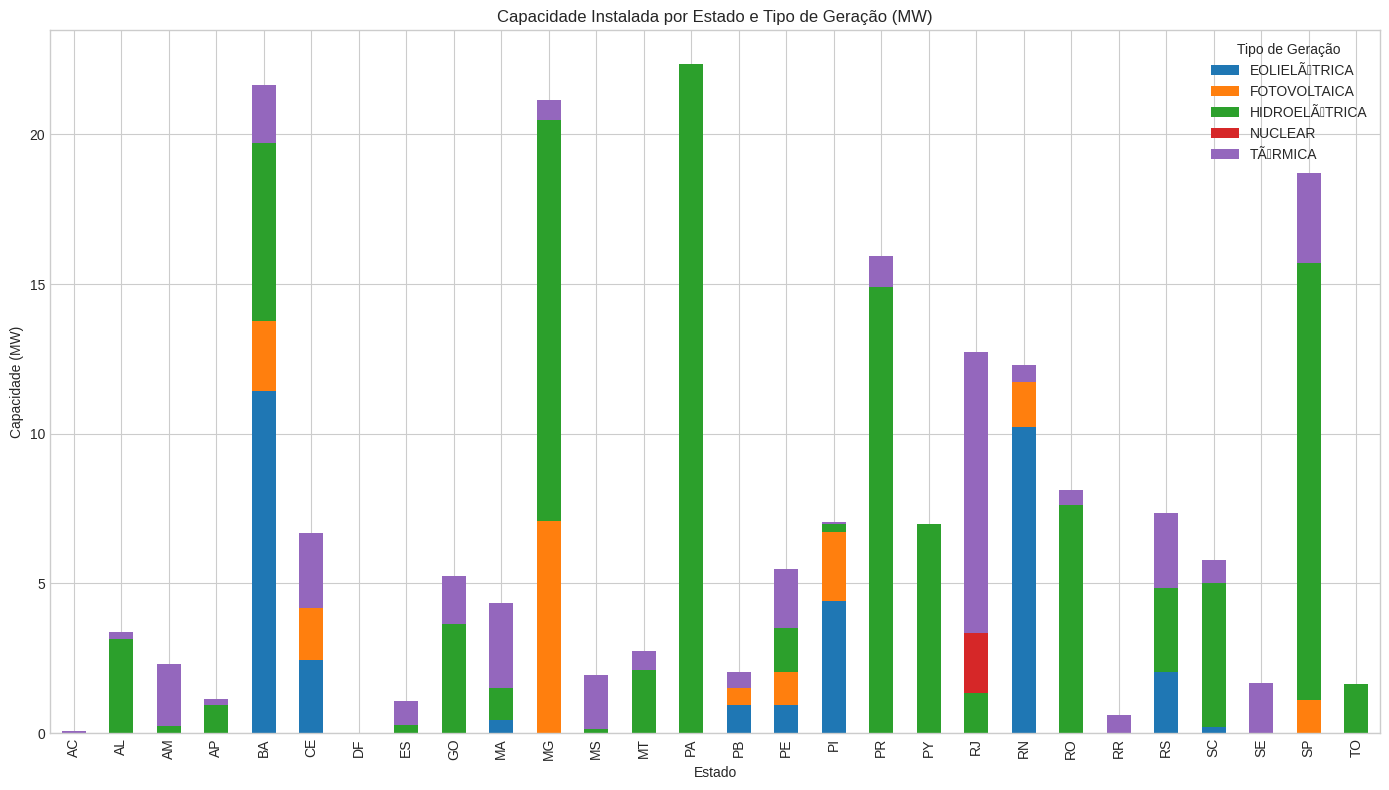

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import unicodedata

# Função para normalizar os nomes das colunas
def normalize_column_names(columns):
    return [
        unicodedata.normalize('NFKD', col)
        .encode('ascii', errors='ignore')
        .decode('utf-8')
        .strip()
        .lower()
        for col in columns
    ]

# 1 - Carregar o dataset
df = pd.read_csv('CAPACIDADE_GERACAO.csv', sep=';', encoding='latin-1')

# Padronizar os nomes das colunas
df.columns = normalize_column_names(df.columns)

print(" Colunas disponíveis no DataFrame:")
print(df.columns.tolist())

# --- Identificar colunas automaticamente ---
def encontrar_coluna(df, palavras_chave):
    for col in df.columns:
        if all(palavra in col for palavra in palavras_chave):
            return col
    return None

col_data = encontrar_coluna(df, ['dat']) or encontrar_coluna(df, ['entrada'])
col_potencia = encontrar_coluna(df, ['potencia']) or 'val_potenciaefetiva'
col_tipo = encontrar_coluna(df, ['tipo', 'usina']) or encontrar_coluna(df, ['tipo', 'geracao'])
col_uf = encontrar_coluna(df, ['uf']) or encontrar_coluna(df, ['estado'])

# Verificação de colunas obrigatórias
if not col_data or not col_potencia or not col_tipo:
    raise ValueError(" Não foi possível identificar as colunas principais (data, potência, tipo). Verifique o CSV.")

print(f"\n Colunas identificadas automaticamente:")
print(f"- Data de entrada: {col_data}")
print(f"- Potência: {col_potencia}")
print(f"- Tipo de usina: {col_tipo}")
if col_uf:
    print(f"- UF/Estado: {col_uf}")
else:
    print(" Nenhuma coluna de UF/Estado encontrada. O agrupamento por estado será ignorado.")

# 2 - Conversões e limpeza
df[col_data] = pd.to_datetime(df[col_data], errors='coerce')
df['ano_operacao'] = df[col_data].dt.year
df.dropna(subset=['ano_operacao'], inplace=True)
df['ano_operacao'] = df['ano_operacao'].astype(int)

df[col_potencia] = pd.to_numeric(df[col_potencia], errors='coerce')
df = df[df[col_potencia] > 0]

# 3 - Explorar tipos de geração
print("\n Tipos de geração encontrados:")
print(df[col_tipo].unique())

# 4 - Evolução da capacidade instalada por tipo de geração
evolucao_anual = (
    df.groupby(['ano_operacao', col_tipo])[col_potencia]
    .sum()
    .unstack()
    .fillna(0)
)

# Calcular acumulado em MW
evolucao_acumulada_mw = evolucao_anual.cumsum() / 1000

# --- Plotar gráfico principal ---
plt.style.use('seaborn-v0_8-whitegrid')
fig, ax = plt.subplots(figsize=(15, 8))
evolucao_acumulada_mw.plot(kind='line', ax=ax, lw=2)

ax.set_title('Evolução da Capacidade Instalada por Tipo de Usina no Brasil', fontsize=16)
ax.set_xlabel('Ano', fontsize=12)
ax.set_ylabel('Capacidade Instalada Acumulada (MW)', fontsize=12)
ax.legend(title='Tipo de Usina')
plt.tight_layout()
plt.show()

# 5 - Crescimento nos últimos 10 anos
ano_final = df['ano_operacao'].max()
ano_inicial = ano_final - 10

if ano_inicial in evolucao_acumulada_mw.index and ano_final in evolucao_acumulada_mw.index:
    capacidade_inicio = evolucao_acumulada_mw.loc[ano_inicial]
    capacidade_fim = evolucao_acumulada_mw.loc[ano_final]
    crescimento_10_anos = capacidade_fim - capacidade_inicio

    fonte_maior_crescimento = crescimento_10_anos.idxmax()
    valor_maior_crescimento = crescimento_10_anos.max()

    print("\n Crescimento nos Últimos 10 Anos por Tipo de Usina (MW):")
    print(crescimento_10_anos.sort_values(ascending=False))
    print(f"\n A fonte que mais cresceu em capacidade instalada nos últimos 10 anos foi: "
          f"'{fonte_maior_crescimento}' com um aumento de {valor_maior_crescimento:,.2f} MW.")
else:
    print("\n Não há dados suficientes para calcular o crescimento dos últimos 10 anos.")

# 6 - (Opcional) Capacidade por estado, se existir coluna de UF
if col_uf:
    capacidade_estado_fonte = (
        df.groupby([col_uf, col_tipo])[col_potencia]
        .sum()
        .unstack()
        .fillna(0) / 1000  # MW
    )

    plt.figure(figsize=(14, 8))
    capacidade_estado_fonte.plot(kind='bar', stacked=True, figsize=(14, 8))
    plt.title('Capacidade Instalada por Estado e Tipo de Geração (MW)')
    plt.xlabel('Estado')
    plt.ylabel('Capacidade (MW)')
    plt.legend(title='Tipo de Geração')
    plt.tight_layout()
    plt.show()



# Exercício 3 – Previsão de Crescimento da Capacidade Solar

### Contexto
A energia solar tem crescido exponencialmente no Brasil. Podemos usar aprendizado de máquina para prever a capacidade futura.

### Atividade
1. Filtrar os dados apenas para usinas solares.  
2. Criar uma série temporal da capacidade instalada por ano.  
3. Aplicar um modelo de regressão (LinearRegression ou RandomForestRegressor).  
4. Fazer previsões para os próximos 5 anos.  
5. Pergunta: O modelo indica crescimento linear ou exponencial?


Colunas disponíveis no DataFrame:
['id_subsistema', 'nom_subsistema', 'id_estado', 'nom_estado', 'nom_modalidadeoperacao', 'nom_agenteproprietario', 'nom_agenteoperador', 'nom_tipousina', 'nom_usina', 'ceg', 'nom_unidadegeradora', 'cod_equipamento', 'num_unidadegeradora', 'nom_combustivel', 'dat_entradateste', 'dat_entradaoperacao', 'dat_desativacao', 'val_potenciaefetiva']

 Colunas identificadas:
- Tipo de geração: nom_tipousina
- Potência: val_potenciaefetiva
- Data: dat_entradaoperacao

 Tipos de geração encontrados:
['HIDROELÃ\x89TRICA' 'TÃ\x89RMICA' 'EOLIELÃ\x89TRICA' 'NUCLEAR'
 'FOTOVOLTAICA']

--- Previsão de Capacidade Solar (MW) ---
Ano: 2026, Previsão de Capacidade Acumulada: 16.55 MW
Ano: 2027, Previsão de Capacidade Acumulada: 18.39 MW
Ano: 2028, Previsão de Capacidade Acumulada: 20.23 MW
Ano: 2029, Previsão de Capacidade Acumulada: 22.07 MW
Ano: 2030, Previsão de Capacidade Acumulada: 23.90 MW


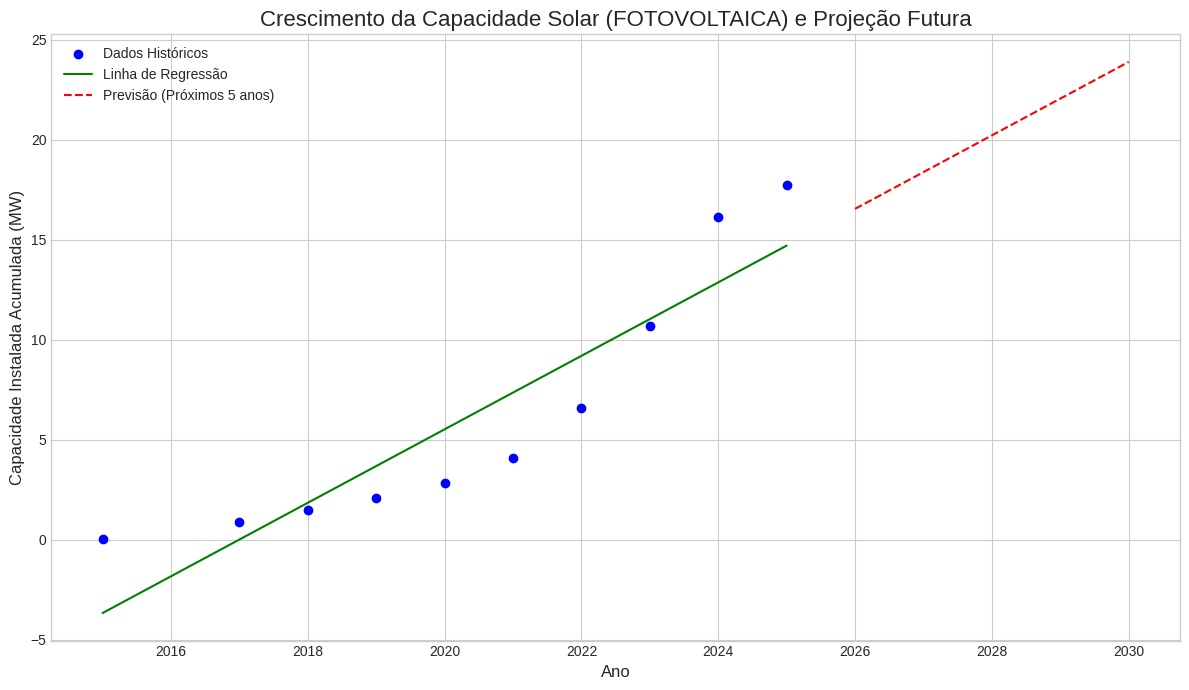


 O modelo de Regressão Linear projeta um crescimento linear.
No entanto, ao observar o gráfico, é provável que o crescimento real da energia solar seja exponencial —
isso significa que o modelo linear pode subestimar o aumento futuro.


In [17]:
from sklearn.linear_model import LinearRegression
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import unicodedata

# -------------------------------
# 1️ Carregar e preparar o dataset
# -------------------------------

def normalize_column_names(columns):
    return [
        unicodedata.normalize('NFKD', col)
        .encode('ascii', errors='ignore')
        .decode('utf-8')
        .strip()
        .lower()
        for col in columns
    ]

df = pd.read_csv('CAPACIDADE_GERACAO.csv', sep=';', encoding='latin-1')
df.columns = normalize_column_names(df.columns)

print("Colunas disponíveis no DataFrame:")
print(df.columns.tolist())

# Função para encontrar colunas automaticamente
def encontrar_coluna(df, palavras_chave):
    for col in df.columns:
        if all(palavra in col for palavra in palavras_chave):
            return col
    return None

col_tipo = encontrar_coluna(df, ['tipo', 'usina'])
col_potencia = encontrar_coluna(df, ['potencia'])
col_data = encontrar_coluna(df, ['dat', 'operacao']) or encontrar_coluna(df, ['dat', 'entrada'])

if not col_tipo or not col_potencia or not col_data:
    raise ValueError("Não foi possível identificar as colunas principais. Verifique o CSV.")

print(f"\n Colunas identificadas:")
print(f"- Tipo de geração: {col_tipo}")
print(f"- Potência: {col_potencia}")
print(f"- Data: {col_data}")

# Converter colunas
df[col_data] = pd.to_datetime(df[col_data], errors='coerce')
df['ano_operacao'] = df[col_data].dt.year
df[col_potencia] = pd.to_numeric(df[col_potencia], errors='coerce')
df = df[df[col_potencia] > 0]
df.dropna(subset=['ano_operacao'], inplace=True)
df['ano_operacao'] = df['ano_operacao'].astype(int)

# -------------------------------
# 2️ Filtrar apenas as usinas solares
# -------------------------------

print("\n Tipos de geração encontrados:")
print(df[col_tipo].unique())

# Ajuste aqui: procurar por "fotovoltaica" em vez de "ufv"
df_solar = df[df[col_tipo].str.contains('fotovoltaica', case=False, na=False)].copy()

if df_solar.empty:
    raise ValueError(" Nenhum registro de usina FOTOVOLTAICA encontrado no dataset.")

# -------------------------------
# 3️ Criar série temporal e aplicar regressão
# -------------------------------

capacidade_solar_anual = (
    df_solar.groupby('ano_operacao')[col_potencia]
    .sum()
    .cumsum() / 1000  # converter para MW
)

# Preparar dados para o modelo
X = capacidade_solar_anual.index.values.reshape(-1, 1)  # anos
y = capacidade_solar_anual.values  # capacidade acumulada

# Regressão linear
model = LinearRegression()
model.fit(X, y)

# -------------------------------
# 4️ Fazer previsões para 5 anos futuros
# -------------------------------

ultimo_ano = int(X.max())
anos_futuros = np.arange(ultimo_ano + 1, ultimo_ano + 6).reshape(-1, 1)
previsoes = model.predict(anos_futuros)

print("\n--- Previsão de Capacidade Solar (MW) ---")
for ano, prev in zip(anos_futuros.flatten(), previsoes):
    print(f"Ano: {ano}, Previsão de Capacidade Acumulada: {prev:,.2f} MW")

# -------------------------------
# 5️ Visualizar os resultados
# -------------------------------

plt.figure(figsize=(12, 7))
plt.scatter(X, y, color='blue', label='Dados Históricos')
plt.plot(X, model.predict(X), color='green', label='Linha de Regressão')
plt.plot(anos_futuros, previsoes, color='red', linestyle='--', label='Previsão (Próximos 5 anos)')
plt.title('Crescimento da Capacidade Solar (FOTOVOLTAICA) e Projeção Futura', fontsize=16)
plt.xlabel('Ano', fontsize=12)
plt.ylabel('Capacidade Instalada Acumulada (MW)', fontsize=12)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# -------------------------------
# 6️ Interpretação do modelo
# -------------------------------

print("\n O modelo de Regressão Linear projeta um crescimento linear.")
print("No entanto, ao observar o gráfico, é provável que o crescimento real da energia solar seja exponencial —")
print("isso significa que o modelo linear pode subestimar o aumento futuro.")



# Exercício 4 – Classificação de Usinas por Fonte

### Contexto
Podemos treinar um modelo de classificação para prever o tipo de geração de uma usina a partir de suas características.

### Atividade
1. Usar variáveis como capacidade, estado, data de operação.  
2. Dividir os dados em treino/teste.  
3. Treinar um modelo de classificação (Decision Tree ou Random Forest).  
4. Avaliar a acurácia do modelo.  
5. Pergunta: Quais variáveis mais influenciam na classificação de uma usina?



 Acurácia do modelo: 96.42%

 Variáveis mais influentes:
                          Variável  Importância
0              val_potenciaefetiva     0.364848
1                     ano_operacao     0.336634
15         nom_estado_MINAS GERAIS     0.063710
22  nom_estado_RIO GRANDE DO NORTE     0.028423
6                 nom_estado_BAHIA     0.027814
27            nom_estado_SAO PAULO     0.021479
21       nom_estado_RIO DE JANEIRO     0.015498
24             nom_estado_RONDONIA     0.015150
7                 nom_estado_CEARA     0.012995
13          nom_estado_MATO GROSSO     0.012387


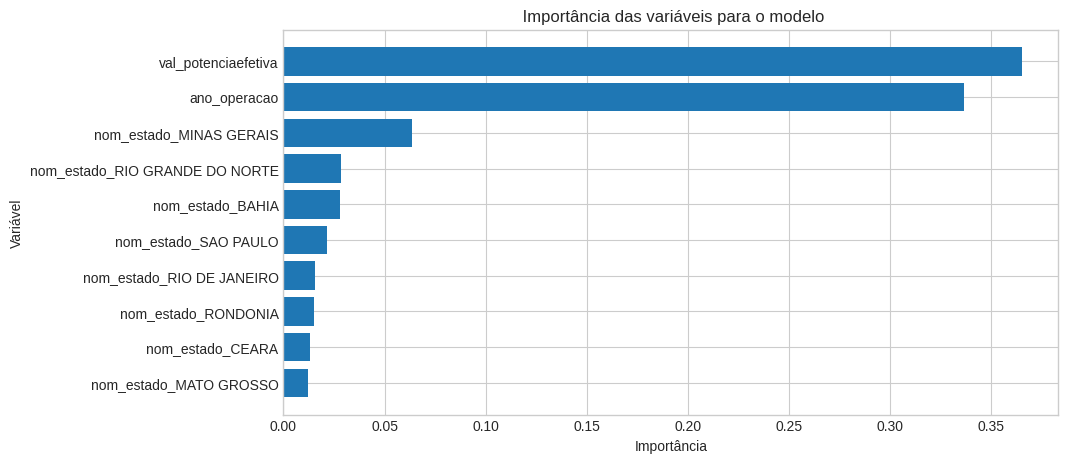


 A potência geralmente é a variável mais influente, seguida pelo estado e o ano de operação.


In [14]:
#  Análise de tipos de usinas com Machine Learning

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

# 1️ Preparação dos dados
df_modelo = df.copy()
df_modelo['ano_operacao'] = pd.to_datetime(df_modelo['dat_entradaoperacao'], errors='coerce').dt.year
df_modelo = df_modelo.dropna(subset=['val_potenciaefetiva', 'nom_tipousina', 'nom_estado', 'ano_operacao'])

# 2️ Escolha das colunas
features = ['val_potenciaefetiva', 'nom_estado', 'ano_operacao']
target = 'nom_tipousina'
tipos_mais_comuns = df_modelo[target].value_counts()[df_modelo[target].value_counts() > 30].index
df_modelo = df_modelo[df_modelo[target].isin(tipos_mais_comuns)]
X = df_modelo[features]
y = df_modelo[target]

# 3️ Divisão treino e teste
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

# 4️ Montagem do modelo
preprocessador = ColumnTransformer(transformers=[
    ('numericas', 'passthrough', ['val_potenciaefetiva', 'ano_operacao']),
    ('categoricas', OneHotEncoder(handle_unknown='ignore'), ['nom_estado'])
])
modelo = Pipeline(steps=[
    ('preprocessador', preprocessador),
    ('classificador', RandomForestClassifier(random_state=42))
])

# 5️ Treinamento
modelo.fit(X_train, y_train)

# 6️ Avaliação
y_pred = modelo.predict(X_test)
acuracia = accuracy_score(y_test, y_pred)
print(f"\n Acurácia do modelo: {acuracia:.2%}")

# 7️ Importância das variáveis
importancias = modelo.named_steps['classificador'].feature_importances_
nomes_estados = modelo.named_steps['preprocessador'].named_transformers_['categoricas'].get_feature_names_out(['nom_estado'])
todas_variaveis = ['val_potenciaefetiva', 'ano_operacao'] + list(nomes_estados)
importancias_df = pd.DataFrame({
    'Variável': todas_variaveis,
    'Importância': importancias
}).sort_values(by='Importância', ascending=False)

print("\n Variáveis mais influentes:")
print(importancias_df.head(10))

# 8️ Visualização
plt.figure(figsize=(10, 5))
plt.barh(importancias_df['Variável'].head(10), importancias_df['Importância'].head(10))
plt.gca().invert_yaxis()
plt.title(' Importância das variáveis para o modelo')
plt.xlabel('Importância')
plt.ylabel('Variável')
plt.show()

# 9️ Interpretação
print("\n A potência geralmente é a variável mais influente, seguida pelo estado e o ano de operação.")



# Exercício 5 – Agrupamento de Usinas por Perfil

### Contexto
Usinas podem ser agrupadas de acordo com sua capacidade, região e tipo de geração, revelando padrões na matriz elétrica.

### Atividade
1. Selecionar variáveis numéricas (capacidade, ano de operação, latitude/longitude se disponíveis).  
2. Aplicar o algoritmo de clusterização K-Means.  
3. Visualizar os clusters em gráfico de dispersão.  
4. Pergunta: Cada grupo representa qual perfil de usinas (pequenas solares, grandes hidráulicas, etc.)?


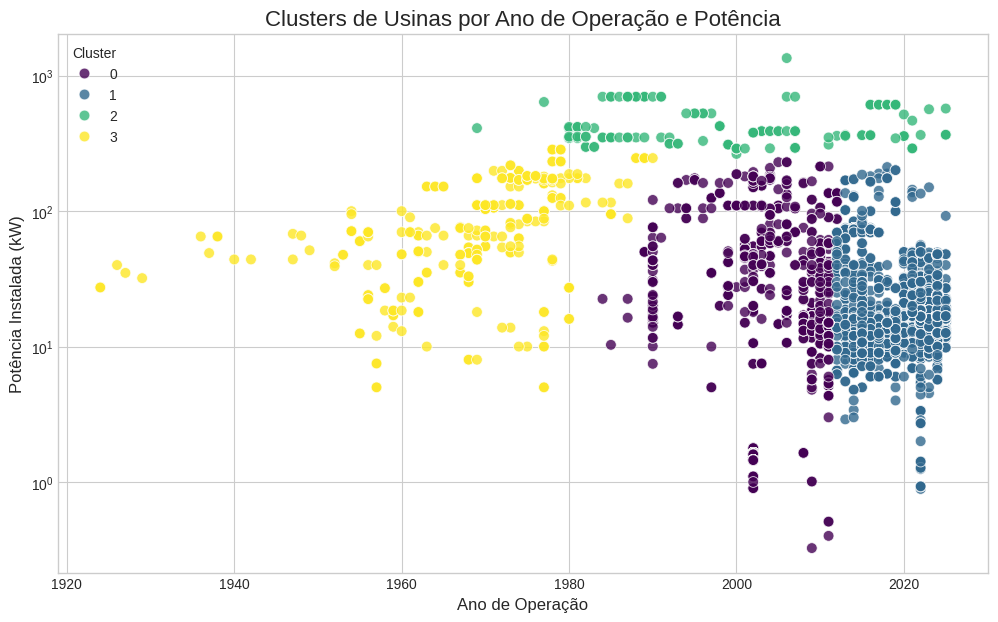


--- Perfil Médio de Cada Cluster ---
         val_potenciaefetiva  ano_operacao
cluster                                   
0                  24.335381   2003.456747
1                  20.420663   2019.824950
2                 454.236104   1999.770833
3                  96.313297   1968.641638

--- Interpretação dos Perfis (Exemplo) ---
Cluster com 'ano_operacao' baixo e 'potencia' alta → grandes hidrelétricas antigas.
Cluster com 'ano_operacao' alto e 'potencia' baixa → usinas solares/eólicas recentes e pequenas.
Cluster intermediário → térmicas e usinas médias.


In [16]:
#  CLUSTERIZAÇÃO DE USINAS POR POTÊNCIA E ANO DE OPERAÇÃO

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore', category=FutureWarning, module='sklearn.cluster._kmeans')

# 1️ Selecionar variáveis relevantes
df_cluster = df.copy()

df_cluster['ano_operacao'] = pd.to_datetime(df_cluster['dat_entradaoperacao'], errors='coerce').dt.year
df_cluster = df_cluster.dropna(subset=['val_potenciaefetiva', 'ano_operacao'])

# 2️ Definir features
features_cluster = ['val_potenciaefetiva', 'ano_operacao']
df_cluster = df_cluster[features_cluster]

# 3️ Padronizar os dados
scaler = StandardScaler()
df_scaled = scaler.fit_transform(df_cluster)

# 4️ Aplicar K-Means
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
df_cluster['cluster'] = kmeans.fit_predict(df_scaled)

# 5️ Visualização dos clusters
plt.figure(figsize=(12, 7))
sns.scatterplot(
    data=df_cluster,
    x='ano_operacao',
    y='val_potenciaefetiva',
    hue='cluster',
    palette='viridis',
    alpha=0.8,
    s=60
)
plt.title('Clusters de Usinas por Ano de Operação e Potência', fontsize=16)
plt.xlabel('Ano de Operação', fontsize=12)
plt.ylabel('Potência Instalada (kW)', fontsize=12)
plt.yscale('log')
plt.legend(title='Cluster')
plt.grid(True)
plt.show()

# 6️ Perfil médio de cada cluster
cluster_profiles = df_cluster.groupby('cluster')[features_cluster].mean()
print("\n--- Perfil Médio de Cada Cluster ---")
print(cluster_profiles)

# 7️ Interpretação dos perfis
print("\n--- Interpretação dos Perfis (Exemplo) ---")
print("Cluster com 'ano_operacao' baixo e 'potencia' alta → grandes hidrelétricas antigas.")
print("Cluster com 'ano_operacao' alto e 'potencia' baixa → usinas solares/eólicas recentes e pequenas.")
print("Cluster intermediário → térmicas e usinas médias.")



# Entrega Final

Cada exercício deve ser entregue em notebook final, vinculado a um repositório do GitHub.  
O relatório final deve conter:
- Código comentado  
- Gráficos e tabelas  
- Respostas às perguntas interpretativas
